
# PREPROCESSING DATA TEKS ULASAN E-COMMERCE
## Analisis Sentimen Berbahasa Indonesia

**Nama:** Fazlul Rahmi Zaini

**NIM:** 24146030

**Program Studi:** Sistem Informasi

**Universitas:** Universitas Abulyatama

### Deskripsi
Praktikum ini bertujuan untuk melakukan
preprocessing terhadap dataset ulasan produk
e-commerce berbahasa Indonesia.

Tahapan yang dilakukan:
1. Case Folding
2. Cleaning
3. Tokenisasi
4. Stopword Removal
5. Stemming


In [1]:

# 1. IMPORT LIBRARY

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import os

from datasets import load_dataset
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

print("Semua library berhasil diimpor!")


Semua library berhasil diimpor!


In [2]:

# 2. DOWNLOAD KEBUTUHAN NLTK

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

print("Persiapan NLTK selesai!")


[nltk_data] Downloading package punkt to C:\Users\USER
[nltk_data]     DK\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\USER
[nltk_data]     DK\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\USER
[nltk_data]     DK\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\USER
[nltk_data]     DK\AppData\Roaming\nltk_data...


Persiapan NLTK selesai!


[nltk_data]   Unzipping corpora\stopwords.zip.


In [3]:

# 3. MENGAMBIL DATASET HUGGING FACE

dataset = load_dataset(
    "dipawidia/ecommerce-product-reviews-sentiment"
)

print("Dataset berhasil diunduh!")

print(dataset)


README.md:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

c:\PREPROCESSING_ECOMMERCE\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USER DK\.cache\huggingface\hub\datasets--dipawidia--ecommerce-product-reviews-sentiment. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


labeledReview.datasetFix.json:   0%|          | 0.00/3.15M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11606 [00:00<?, ? examples/s]

Dataset berhasil diunduh!
DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})


In [4]:

# 4. KONVERSI DATASET KE DATAFRAME

df = dataset["train"].to_pandas()

print("Dataset berhasil dikonversi!")

display(df.head())


Dataset berhasil dikonversi!


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


In [5]:

# 5. INFORMASI DATASET

print("JUMLAH DATA:")
print(len(df))

print("\nJUMLAH KOLOM:")
print(len(df.columns))

print("\nNAMA KOLOM:")
print(df.columns.tolist())

print("\nINFORMASI DATA:")
df.info()

print("\nDATA KOSONG:")
print(df.isnull().sum())

print("\nLIMA DATA PERTAMA:")
display(df.head())


JUMLAH DATA:
11606

JUMLAH KOLOM:
3

NAMA KOLOM:
['review', 'translate', 'sentimen']

INFORMASI DATA:
<class 'pandas.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     11606 non-null  str  
 1   translate  11606 non-null  str  
 2   sentimen   11606 non-null  int64
dtypes: int64(1), str(2)
memory usage: 2.6 MB

DATA KOSONG:
review       0
translate    0
sentimen     0
dtype: int64

LIMA DATA PERTAMA:


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


DISTRIBUSI SENTIMEN
Negatif: 5803 data (50.00%)
Positif: 5803 data (50.00%)


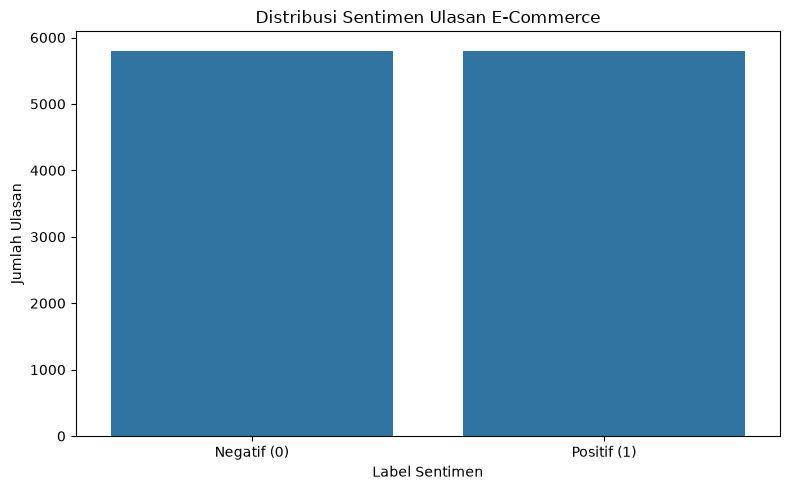

In [6]:

# 6. DISTRIBUSI LABEL SENTIMEN

# Menghitung jumlah masing-masing label
distribusi = df["sentimen"].value_counts().sort_index()

print("DISTRIBUSI SENTIMEN")

for label, jumlah in distribusi.items():

    if label == 0:
        nama = "Negatif"
    elif label == 1:
        nama = "Positif"
    else:
        nama = f"Label {label}"

    persentase = jumlah / len(df) * 100

    print(
        f"{nama}: {jumlah} data "
        f"({persentase:.2f}%)"
    )

# Membuat grafik
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentimen",
    order=sorted(df["sentimen"].dropna().unique())
)

plt.title("Distribusi Sentimen Ulasan E-Commerce")
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Ulasan")

plt.xticks([0, 1], ["Negatif (0)", "Positif (1)"])

plt.tight_layout()

# Menyimpan grafik
os.makedirs("data", exist_ok=True)

plt.savefig(
    "data/grafik_distribusi_sentimen.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:

# 7. PERSIAPAN STOPWORD DAN STEMMING

# Membuat stemmer bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Mengambil stopword bahasa Indonesia
stop_words = set(
    stopwords.words("indonesian")
)

# Mempertahankan kata negasi
negasi = {
    "tidak",
    "bukan",
    "belum",
    "jangan",
    "kurang",
    "tanpa"
}

stop_words = stop_words - negasi

print("Stopword dan stemming siap digunakan!")


Stopword dan stemming siap digunakan!


In [8]:

# 8. CASE FOLDING

def case_folding(text):

    return str(text).lower()


# Pengujian
contoh = "PRODUK INI SANGAT BAGUS"

hasil = case_folding(contoh)

print("Sebelum:", contoh)
print("Sesudah:", hasil)


Sebelum: PRODUK INI SANGAT BAGUS
Sesudah: produk ini sangat bagus


In [9]:

# 9. CLEANING

def cleaning(text):

    # Menghapus URL
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Menghapus angka
    text = re.sub(
        r"\d+",
        " ",
        text
    )

    # Menghapus tanda baca dan karakter khusus
    text = re.sub(
        r"[^\w\s]",
        " ",
        text
    )

    # Menghapus underscore
    text = re.sub(
        r"_",
        " ",
        text
    )

    # Menghapus spasi berlebihan
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


# Pengujian
contoh = "Produk BAGUS!!! Harga 50000 www.toko.com"

hasil = cleaning(contoh)

print("Sebelum:", contoh)
print("Sesudah:", hasil)


Sebelum: Produk BAGUS!!! Harga 50000 www.toko.com
Sesudah: Produk BAGUS Harga


In [10]:

# 10. TOKENISASI

def tokenisasi(text):

    return word_tokenize(text)


# Pengujian
contoh = "produk ini sangat bagus"

hasil = tokenisasi(contoh)

print("Kalimat:", contoh)
print("Hasil tokenisasi:", hasil)


Kalimat: produk ini sangat bagus
Hasil tokenisasi: ['produk', 'ini', 'sangat', 'bagus']


In [11]:

# 11. STOPWORD REMOVAL

def stopword_removal(tokens):

    hasil = [
        kata for kata in tokens
        if kata not in stop_words
    ]

    return hasil


# Pengujian
contoh = "produk ini sangat bagus"

tokens = tokenisasi(contoh)

hasil = stopword_removal(tokens)

print("Sebelum:", tokens)
print("Sesudah:", hasil)


Sebelum: ['produk', 'ini', 'sangat', 'bagus']
Sesudah: ['produk', 'bagus']


In [12]:

# 12. STEMMING

def stemming(tokens):

    hasil = [
        stemmer.stem(kata)
        for kata in tokens
    ]

    return hasil


# Pengujian
contoh = [
    "membeli",
    "pengiriman",
    "pelayanan"
]

hasil = stemming(contoh)

print("Sebelum:", contoh)
print("Sesudah:", hasil)


Sebelum: ['membeli', 'pengiriman', 'pelayanan']
Sesudah: ['beli', 'kirim', 'layan']


In [13]:

# 13. FUNGSI PREPROCESSING LENGKAP

def preprocessing(text):

    # Case Folding
    text = case_folding(text)

    # Cleaning
    text = cleaning(text)

    # Tokenisasi
    tokens = tokenisasi(text)

    # Stopword Removal
    tokens = stopword_removal(tokens)

    # Stemming
    tokens = stemming(tokens)

    # Menggabungkan kembali kata
    hasil = " ".join(tokens)

    return hasil


print("Fungsi preprocessing berhasil dibuat!")


Fungsi preprocessing berhasil dibuat!


In [14]:

# 14. MENERAPKAN PREPROCESSING KE DATASET

# Menghapus data yang tidak memiliki ulasan
df = df.dropna(subset=["review"]).copy()

# Memastikan seluruh ulasan berbentuk string
df["review"] = df["review"].astype(str)

# Membuat kolom baru
df["review_preprocessing"] = df["review"].apply(
    preprocessing
)

print("Seluruh proses preprocessing selesai!")

display(
    df[
        [
            "review",
            "review_preprocessing",
            "sentimen"
        ]
    ].head()
)


Seluruh proses preprocessing selesai!


,review,review_preprocessing,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...,0
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih,1
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek tolong perhati,0
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk harga jangkau kirim cepet bang...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi packaging kurang p...,0


In [15]:

# 15. MENAMPILKAN 10 CONTOH SEBELUM DAN SESUDAH

pd.set_option(
    "display.max_colwidth",
    None
)

contoh_10 = df[
    [
        "review",
        "review_preprocessing",
        "sentimen"
    ]
].head(10).copy()

contoh_10.insert(
    0,
    "No",
    range(1, len(contoh_10) + 1)
)

contoh_10.columns = [
    "No",
    "Teks Sebelum Preprocessing",
    "Teks Sesudah Preprocessing",
    "Sentimen"
]

display(contoh_10)


,No,Teks Sebelum Preprocessing,Teks Sesudah Preprocessing,Sentimen
0,1,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg ga nyala,0
1,2,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih,1
2,3,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek tolong perhati,0
3,4,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk harga jangkau kirim cepet banget udh x order oke tp sayang klo kado gabisa nitip pake kartu ucap bungkus pake kertas kado,0
4,5,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi packaging kurang penyot robek,0
5,6,"Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.",produk original kualitas cepat kirim sanagt cepat recommended seller,1
6,7,kualitas sangat jelek. bocor,kualitas jelek bocor,0
7,8,"terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka",terimakasih ka ya barang terima sukses ka,1
8,9,"Body nya lebih berat dari cm 1579, spiral nya lebih tipis dibanding cm 1579, semoga awet, beli CM 1659 penasaran Aja, yang cm 1579 udah mau rusak mesin nya, Harga lebih murah 4k dari cm 1579 Fast delivery, courier Ramah sangat, ty seller",body nya berat cm spiral nya tipis banding cm moga awet beli cm penasaran aja cm udah rusak mesin nya harga murah k cm fast delivery courier ramah ty seller,0
9,10,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 dan ternyata tab SKETSA ADVAN tidak bisa di nyalakan sama sekali dan di cas juga posisi Tab tidak bisa menyala,pesan terima tanggal january buka pagi tanggal january tab sketsa advan tidak nyala cas posisi tab tidak nyala,0


In [16]:

# 16. MENYIMPAN HASIL PREPROCESSING

os.makedirs("data", exist_ok=True)

# Menyimpan seluruh hasil
df.to_csv(
    "data/hasil_preprocessing.csv",
    index=False,
    encoding="utf-8-sig"
)

# Menyimpan 10 contoh
contoh_10.to_csv(
    "data/10_contoh_preprocessing.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Semua file CSV berhasil disimpan!")


Semua file CSV berhasil disimpan!


In [17]:

# 17. RINGKASAN HASIL AKHIR

print("====================================")
print("RINGKASAN HASIL PREPROCESSING")
print("====================================")

print("Jumlah data awal: 11.606")

print("Jumlah data setelah pembersihan:", len(df))

print("Jumlah kolom:", len(df.columns))

print(
    "Jumlah ulasan yang telah diproses:",
    df["review_preprocessing"].notna().sum()
)

print(
    "Jumlah hasil preprocessing kosong:",
    (df["review_preprocessing"].str.strip() == "").sum()
)

print("\nDistribusi sentimen:")

print(df["sentimen"].value_counts())

print("\nPREPROCESSING BERHASIL DISELESAIKAN!")


RINGKASAN HASIL PREPROCESSING
Jumlah data awal: 11.606
Jumlah data setelah pembersihan: 11606
Jumlah kolom: 4
Jumlah ulasan yang telah diproses: 11606
Jumlah hasil preprocessing kosong: 13

Distribusi sentimen:
sentimen
0    5803
1    5803
Name: count, dtype: int64

PREPROCESSING BERHASIL DISELESAIKAN!
